# QE007: Kirchhoff-Consistent Synthetic Grid

**Can a quantum circuit help generate fake electricity-grid data that still obeys the laws of physics?**

Electricity companies need realistic grid data to plan new cables and transformers. Real household data is private, so
one idea is to train a model that produces *synthetic* data: artificial days that look like the real ones but belong
to no real household. The catch is that grid data is not just numbers. Loads (how much power each house uses) and
voltages are tied together by Kirchhoff's laws. A model that ignores this produces a grid that could not exist.

This exercise has two parts:

* **Part A (one exact answer, Euler-style):** solve the power flow on a small street feeder and report the lowest voltage.
* **Part B (study):** train four generators on one simulated year of data, including one built on a 7-qubit quantum
  circuit, and check which ones respect the physics and the risk.

### Words used in this notebook

| term | meaning |
|---|---|
| **feeder** | the cable that runs from a neighbourhood transformer down a street, with houses connected along it |
| **bus** | a connection point on the feeder: the transformer is bus 0, the houses are buses 1 to 7 |
| **load connection** | a bus where a customer (here: a household or small group of households) draws power |
| **parent bus** | the next bus *upstream*, towards the transformer. Power reaches bus k only through its parent, so the feeder is a tree |
| **pu (per unit)** | values divided by a chosen reference so they are easy to compare. Voltage 1.0 pu = the normal 230 V; 0.95 pu = 5% too low. Power 1 pu = 100 kVA here, so 0.07 pu = 7 kW |
| **rₖ, xₖ** | resistance and reactance of the cable segment that feeds bus k, in pu. They decide how much voltage is lost along the cable |
| **sₖ** | size factor of the customer at bus k: 1.0 is a typical household, 1.3 uses 30% more |
| **power flow** | solving Kirchhoff's laws to get every bus voltage from the loads |
| **EV** | electric vehicle; a home charger draws about 7 kW, several times a normal household |
| **random seed** | a number that fixes the random draws, so every run of the notebook gives the same results |

The numbers for rₖ and sₖ are *chosen*, not measured. They are typical of a European low-voltage street cable and
ordinary households, and are tuned so that a few EVs charging together push the far end of the street close to the
0.95 pu legal limit. Feel free to change them.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.optimize import minimize

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
BLUE, ORANGE, GREEN, GRAY, INK = "#2a78d6", "#eb6834", "#1f9e6e", "#8a8984", "#0b0b0b"

## 1. The feeder

Eight buses in a tree. Bus 0 is the transformer and is held at exactly 1.0 pu. Each other bus hangs off its parent
through one cable segment. Buses 3, 4, 6 and 7 have 6 kW rooftop solar panels (PV).

```
  T(0) ── 1 ── 2 ── 3 ── 4 ── 7
               │
               5 ── 6
```

In [2]:
PARENT = np.array([-1, 0, 1, 2, 3, 2, 5, 4])                      # parent of bus k (bus 0 has none)
R_LINE = np.array([0, .035, .035, .035, .035, .045, .045, .045])   # cable resistance r_k (pu)
X_LINE = 0.5 * R_LINE                                              # cable reactance x_k = r_k / 2 (pu)
SIZE   = np.array([1.0, 1.1, 0.9, 1.2, 0.8, 1.0, 1.3])            # size factor s_k of buses 1..7
HAS_PV = np.array([0, 0, 1, 1, 0, 1, 1], bool)                     # rooftop solar on buses 3, 4, 6, 7

NB, NL, H = 8, 7, 24          # number of buses, load buses, hours in a day
V_LIMIT   = 0.95              # lowest allowed voltage (pu)
TANPHI    = 0.25              # reactive power = 0.25 x active power for household demand
EV_PU, EV_HOURS, EV_STARTS = 0.07, 3, (18, 19, 20)   # 7 kW charger, 3 hours, starts at 18, 19 or 20h

t = np.arange(H)
bump = lambda centre, width: np.exp(-0.5 * ((t - centre) / width) ** 2)
HOUSE = 0.02 * (0.4 + 0.6 * bump(7.5, 1.2) + 1.3 * bump(19, 2.0))   # typical household (pu): morning + evening peak
SOLAR = 0.06 * np.clip(np.sin(np.pi * (t - 6) / 14), 0, None) * (t >= 6) * (t <= 20)  # 6 kW panel, clear day

# pairs of neighbouring load buses (used later by the correlated-EV models and the quantum circuit)
EDGES = [(PARENT[k] - 1, k - 1) for k in range(2, NB)]
print("neighbouring load-bus pairs:", [(int(a) + 1, int(b) + 1) for a, b in EDGES])

neighbouring load-bus pairs: [(1, 2), (2, 3), (3, 4), (2, 5), (5, 6), (4, 7)]


## 2. Power flow: from loads to voltages

On a tree-shaped feeder the power flow can be solved with a simple **backward/forward sweep**:

1. Guess every voltage is 1.0 pu.
2. **Backward:** each house draws current $I_k = \overline{S_k / V_k}$. Walk from the far end towards the transformer,
   adding up currents: the current in a cable = its own bus current + the currents of everything further down
   (Kirchhoff's current law).
3. **Forward:** walk from the transformer outwards: $V_k = V_{parent} - z_k \cdot I_{cable,k}$, where
   $z_k = r_k + j\,x_k$ (Kirchhoff's voltage law / Ohm's law).
4. Repeat until nothing changes.

$S_k = P_k + jQ_k$ is the complex power. P is the real (active) power that does work; Q is reactive power
that motors and electronics also draw. The function handles any number of days and hours at once.

In [3]:
def power_flow(P):
    # P: array (..., 24, 7) of net load in pu at buses 1..7 (positive = consuming, negative = solar export)
    # returns |V| in pu with the same shape
    Q = TANPHI * np.clip(P, 0, None)                         # solar panels give no reactive power
    S = np.concatenate([np.zeros(P.shape[:-1] + (1,)), P + 1j * Q], axis=-1)   # add bus 0
    V = np.ones(S.shape, complex)
    for _ in range(50):
        I = np.conj(S / V)                                   # current drawn at each bus
        for k in range(NB - 1, 0, -1):                       # backward: push currents upstream
            I[..., PARENT[k]] += I[..., k]
        V_new = np.empty_like(V); V_new[..., 0] = 1.0
        for k in range(1, NB):                               # forward: voltage drop along each cable
            V_new[..., k] = V_new[..., PARENT[k]] - (R_LINE[k] + 1j * X_LINE[k]) * I[..., k]
        converged = np.max(np.abs(V_new - V)) < 1e-12
        V = V_new
        if converged:
            break
    return np.abs(V[..., 1:])

def ev_load(z, start):
    # z: which buses charge an EV (0/1), start: start hour per bus  ->  EV load (..., 24, 7)
    on = (t[:, None] >= start[..., None, :]) & (t[:, None] < start[..., None, :] + EV_HOURS)
    return z[..., None, :] * on * EV_PU

## Part A: the exact answer

**Reference evening.** Every household follows the typical profile (scaled by its size sₖ), the sun shines fully, and
**every one of the 7 EVs starts charging at 18:00**. Net load at bus k in hour t:

$$P_k(t) = s_k\,h(t) - \text{PV}_k\,g(t) + e_k(t)$$

**Task:** find the lowest voltage $V_{min}$ over all 24 hours and all 7 houses, and report
$A = \lfloor 10^6 \cdot V_{min} \rfloor$.

*Check value:* with no EVs at all, $V_{min}$ = 0.973597… pu, so that version of the answer would be 973597.

In [4]:
P_ref_noEV = HOUSE[:, None] * SIZE - SOLAR[:, None] * HAS_PV
P_ref = P_ref_noEV + ev_load(np.ones(NL), np.full(NL, 18))

print(f"check, no EVs : V_min = {power_flow(P_ref_noEV).min():.6f} pu")
V_ref = power_flow(P_ref)
V_min = V_ref.min()
hour, bus = np.unravel_index(V_ref.argmin(), V_ref.shape)
A = int(np.floor(1e6 * V_min + 1e-9))
print(f"all EVs at 18h: V_min = {V_min:.9f} pu at bus {bus + 1}, {hour}:00")
print(f"bus-hours below {V_LIMIT} pu: {(V_ref < V_LIMIT).sum()}")
print(f"\nANSWER  A = {A}")

check, no EVs : V_min = 0.973597 pu
all EVs at 18h: V_min = 0.914686722 pu at bus 7, 20:00
bus-hours below 0.95 pu: 17

ANSWER  A = 914686


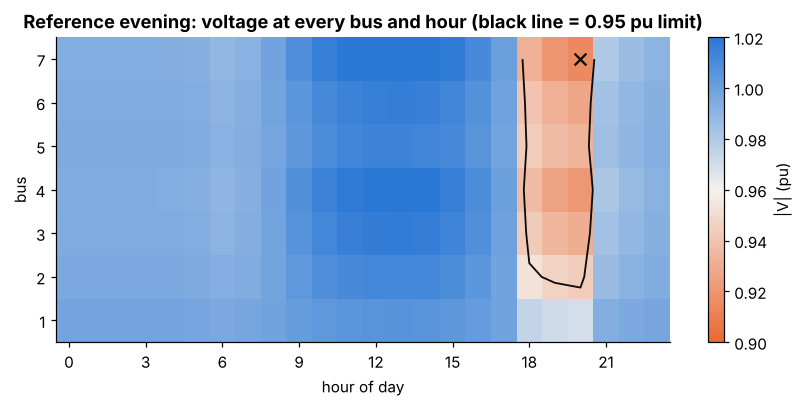

In [5]:
cmap = LinearSegmentedColormap.from_list("v", [ORANGE, "#f4f2ee", BLUE])
fig, ax = plt.subplots(figsize=(9, 3.6))
im = ax.imshow(V_ref.T, aspect="auto", cmap=cmap, vmin=0.90, vmax=1.02, origin="lower", extent=[-0.5, 23.5, 0.5, 7.5])
ax.contour(t, np.arange(1, 8), V_ref.T, levels=[V_LIMIT], colors=INK, linewidths=1.2)
ax.scatter(hour, bus + 1, marker="x", color=INK, s=60)
ax.set_xlabel("hour of day"); ax.set_ylabel("bus"); ax.set_xticks(range(0, 24, 3))
ax.set_title(f"Reference evening: voltage at every bus and hour (black line = {V_LIMIT} pu limit)")
plt.colorbar(im, ax=ax, label="|V| (pu)"); plt.show()

Solar lifts voltages at midday (blue). The 18:00–21:00 EV block pulls buses 3 to 7 (and briefly bus 2)
below the limit, with the worst point at bus 7, the last house on the longest branch.

---

## Part B: the study

### 3. A simulated "real" world

To judge a generator we need to know the truth, so we build a simulated world and pretend its output is real data.
Compared with the reference evening, each day now varies:

* demand is higher in winter, and every hour gets ±15% random noise,
* solar output depends on the season and on clouds,
* each house's EV charges or not, starting at 18, 19 or 20h.

**The key ingredient: EV charging is contagious.** Neighbours tend to charge on the same evenings (same tariff, same
habits). We model which houses charge, $z = (z_1,\dots,z_7)$ with $z_k \in \{0,1\}$, with an **Ising distribution**,
the same formula physicists use for magnetic spins:

$$p(z) \propto \exp\Big( h \sum_k z_k + J \sum_{\text{neighbours } (k,l)} z_k z_l \Big), \qquad h=-2.1,\; J=1.5$$

h < 0 makes charging fairly rare; J > 0 rewards neighbours charging together. With only 7 houses there are
$2^7 = 128$ possible patterns, so we can write down every probability exactly.

In [6]:
H_FIELD, J_COUP = -2.1, 1.5
STATES = ((np.arange(2 ** NL)[:, None] >> np.arange(NL)[::-1]) & 1).astype(float)   # all 128 patterns
TO_INDEX = 2 ** np.arange(NL)[::-1]

def ising_probs(h, J):
    energy = STATES @ h + sum(J[i] * STATES[:, a] * STATES[:, b] for i, (a, b) in enumerate(EDGES))
    p = np.exp(energy - energy.max())
    return p / p.sum()

P_TRUE = ising_probs(np.full(NL, H_FIELD), np.full(len(EDGES), J_COUP))

def real_days(n, rng, first_day=0):
    day = (first_day + np.arange(n)) % 365
    season = 1 + 0.25 * np.cos(2 * np.pi * day / 365)                       # winter peak
    sun = rng.beta(2, 2, n) * (1 - 0.35 * np.cos(2 * np.pi * day / 365))    # summer peak, random clouds
    noise = rng.lognormal(0, 0.15, (n, H, NL))
    z = STATES[rng.choice(2 ** NL, n, p=P_TRUE)]                            # who charges tonight
    start = rng.choice(EV_STARTS, (n, NL))
    P = HOUSE[None, :, None] * SIZE * season[:, None, None] * noise \
        - sun[:, None, None] * SOLAR[None, :, None] * HAS_PV + ev_load(z, start)
    return P, z

n_charging = STATES.sum(1)
indep = np.prod(np.where(STATES > 0, P_TRUE @ STATES, 1 - P_TRUE @ STATES), 1)
print("chance each house charges on a given evening:", (P_TRUE @ STATES).round(2))
print("P(6 or more EVs at once) with contagion:     ", round(P_TRUE[n_charging >= 6].sum(), 5))
print("P(6 or more EVs at once) if houses were independent:", round(indep[n_charging >= 6].sum(), 5))

chance each house charges on a given evening: [0.18 0.28 0.24 0.21 0.23 0.16 0.16]
P(6 or more EVs at once) with contagion:      0.00817
P(6 or more EVs at once) if houses were independent: 0.00044


The same per-house charging rates give very different chances of a "crowded" evening, depending on whether houses
influence each other. Crowded evenings are exactly the ones that break the voltage limit.

**Data.** One year (365 days) is the training data. A separate 20,000 days from the same world serve as the
ground truth when scoring.

The electricity company does not see EV flags directly, only loads. So we *detect* an EV as a jump above 6 kW in
the evening, and check how often the detector is right.

In [7]:
rng = np.random.default_rng(0)                       # random seed 0: same results on every run
P_train, z_train = real_days(365, rng)
V_train = power_flow(P_train)
P_truth, _ = real_days(20000, rng)
V_truth = power_flow(P_truth)

def detect_ev(P):
    jump = P[:, 17:23, :] > 0.06
    z = jump.any(1).astype(float)
    start = np.where(z > 0, 17 + jump.argmax(1), 18)
    return z, np.clip(start, EV_STARTS[0], EV_STARTS[-1])

z_seen, start_seen = detect_ev(P_train)
print(f"EV detector correct on {100 * (z_seen == z_train).mean():.1f}% of house-evenings")
print(f"true share of days with a voltage problem: {100 * (V_truth.min((1, 2)) < V_LIMIT).mean():.1f}%")

EV detector correct on 98.7% of house-evenings
true share of days with a voltage problem: 20.8%


### 4. Four generators

All four learn only from the one training year.

| # | generator | how it makes loads | who charges an EV | how it makes voltages |
|---|---|---|---|---|
| 1 | **Gaussian, no physics** | learns loads *and* voltages together as one big list of numbers | (implicit) | invents them directly |
| 2 | **Independent EVs + physics** | Gaussian model of the non-EV load | each house on its own coin flip | **power flow** |
| 3 | **Classical correlated + physics** | same | an Ising model fitted to the data | **power flow** |
| 4 | **Quantum circuit + physics** | same | a 7-qubit quantum circuit | **power flow** |

**The Gaussian model.** It reduces each day to its 12 most important patterns of variation (principal component
analysis, PCA), learns how strongly each pattern varies, then creates new days by mixing those patterns at random and
adding a little noise. This is probabilistic PCA, a simple, transparent stand-in for the neural-network generators used
in practice.

Generators 2–4 put physics in as a **hard rule**: they only generate loads, and the voltages are always computed by
`power_flow`. Generator 1 is the "black box" that has to *learn* Kirchhoff from examples.

In [8]:
class GaussianGenerator:
    # probabilistic PCA: keep the k strongest patterns, treat the rest as small random noise
    def __init__(self, k=12):
        self.k = k
    def fit(self, X):
        self.mean, self.std = X.mean(0), X.std(0) + 1e-12
        Z = (X - self.mean) / self.std
        _, s, Vt = np.linalg.svd(Z, full_matrices=False)
        var = s ** 2 / (len(Z) - 1)
        self.noise = var[self.k:].mean()
        self.W = Vt[:self.k].T * np.sqrt(np.clip(var[:self.k] - self.noise, 0, None))
        return self
    def sample(self, n, rng):
        Z = rng.standard_normal((n, self.k)) @ self.W.T + np.sqrt(self.noise) * rng.standard_normal((n, len(self.mean)))
        return Z * self.std + self.mean

# generator 1: loads and voltages glued into one list of 24*7 + 24*7 = 336 numbers per day
gen1 = GaussianGenerator().fit(np.concatenate([P_train.reshape(365, -1), V_train.reshape(365, -1)], axis=1))

# generators 2-4 share this model of the household + solar part (EV block removed)
base_load = (P_train - ev_load(z_seen, start_seen)).reshape(365, -1)
gen_base = GaussianGenerator().fit(base_load)

# EV pattern models: count how often each of the 128 patterns was seen
seen = np.bincount((z_seen @ TO_INDEX).astype(int), minlength=2 ** NL) / 365
rate = z_seen.mean(0)
p_independent = np.prod(np.where(STATES > 0, rate, 1 - rate), axis=1)          # generator 2

def fit_ising(empirical):                                                        # generator 3
    nll = lambda th: -empirical @ np.log(ising_probs(th[:NL], th[NL:]) + 1e-300)
    th = minimize(nll, np.zeros(NL + len(EDGES)), method="L-BFGS-B").x
    return ising_probs(th[:NL], th[NL:])

p_ising = fit_ising(seen)
print("generators 1-3 ready")

generators 1-3 ready


### 5. The quantum circuit (generator 4)

A **quantum circuit Born machine** turns a quantum state into a sampler. Measuring a quantum state of 7 qubits gives
one of the 128 bit patterns, with probability $|\langle z|\psi\rangle|^2$ (the Born rule). If we tune the circuit so
those probabilities match the data, every measurement is a new synthetic "who charges tonight" pattern.

**Design: one qubit per house, wires where the street has cables.**

* **RY(θ) rotation** on each qubit: sets how likely that house is to charge.
* **CZ gate** between two qubits: links two houses. We place a CZ *only between neighbouring houses on the feeder*, so
  the circuit's layout copies the street.

We use 3 layers of [RY on all qubits → CZ on every neighbour pair], then a last RY layer: 4 × 7 = 28 angles to learn.

**Training.** We need a score for how far the circuit's distribution is from the patterns seen in the data. We use the
**maximum mean discrepancy (MMD)**, which compares the two distributions while treating nearby patterns (differing in
one or two houses) as similar. This keeps the circuit from just memorising the 365 days. Gradients come from the
**parameter-shift rule**, the standard way to differentiate quantum circuits: run the circuit with each angle shifted
by ±90° and take half the difference.

The circuit is simulated exactly on the computer (a list of 128 amplitudes), so no quantum hardware or extra library is
needed.

In [9]:
class BornMachine:
    def __init__(self, layers=3):
        self.L = layers
        self.cz = np.ones(2 ** NL)                          # a CZ flips the sign when both qubits are 1
        for a, b in EDGES:
            self.cz *= 1 - 2 * STATES[:, a] * STATES[:, b]

    def amplitudes(self, theta):
        theta = theta.reshape(self.L + 1, NL)
        psi = np.zeros(2 ** NL); psi[0] = 1.0              # start in |0000000>
        for layer in range(self.L + 1):
            psi = psi.reshape((2,) * NL)
            for q in range(NL):                            # RY rotation on qubit q
                c, s = np.cos(theta[layer, q] / 2), np.sin(theta[layer, q] / 2)
                psi = np.moveaxis(psi, q, 0)
                psi = np.stack([c * psi[0] - s * psi[1], s * psi[0] + c * psi[1]])
                psi = np.moveaxis(psi, 0, q)
            psi = psi.reshape(-1)
            if layer < self.L:
                psi = psi * self.cz                        # CZ on every feeder neighbour pair
        return psi

    def probs(self, theta):
        return self.amplitudes(theta) ** 2                 # Born rule

    def fit(self, empirical, rng, restarts=3):
        hamming = np.abs(STATES[:, None, :] - STATES[None]).sum(-1)   # houses that differ between two patterns
        K = sum(np.exp(-hamming / w) for w in (0.5, 1, 2, 4))
        mmd = lambda th: (self.probs(th) - empirical) @ K @ (self.probs(th) - empirical)
        def grad(th):                                      # parameter-shift rule
            d = 2 * K @ (self.probs(th) - empirical)
            g = np.empty_like(th)
            for i in range(len(th)):
                shift = np.zeros_like(th); shift[i] = np.pi / 2
                g[i] = d @ (self.probs(th + shift) - self.probs(th - shift)) / 2
            return g
        best = None
        for _ in range(restarts):
            res = minimize(mmd, rng.normal(0, 0.3, (self.L + 1) * NL), jac=grad,
                           method="L-BFGS-B", options={"maxiter": 400})
            if best is None or res.fun < best.fun:
                best = res
        self.theta = best.x
        return self.probs(best.x)

t0 = time.time()
born = BornMachine()
p_quantum = born.fit(seen, rng)
print(f"Born machine trained in {time.time() - t0:.0f} s with {born.theta.size} angles")
print("most likely patterns (house 1..7):")
for i in np.argsort(p_quantum)[::-1][:5]:
    print(f"  {''.join(str(int(b)) for b in STATES[i])}   circuit {p_quantum[i]:.3f}   truth {P_TRUE[i]:.3f}")

Born machine trained in 57 s with 28 angles
most likely patterns (house 1..7):
  0000000   circuit 0.285   truth 0.314
  0000001   circuit 0.054   truth 0.038
  0100000   circuit 0.045   truth 0.038
  0000100   circuit 0.045   truth 0.038
  1000000   circuit 0.042   truth 0.038


### 6. Generate 4,000 synthetic days with each model

In [10]:
N_SYN = 4000

def physics_generator(p_ev):
    z = STATES[rng.choice(2 ** NL, N_SYN, p=p_ev)]
    start = rng.choice(start_seen[z_seen > 0], (N_SYN, NL))
    P = gen_base.sample(N_SYN, rng).reshape(N_SYN, H, NL) + ev_load(z, start)
    return P, power_flow(P)                              # voltages always from Kirchhoff

X = gen1.sample(N_SYN, rng)
models = {
    "1 Gaussian, no physics":   (X[:, :H * NL].reshape(N_SYN, H, NL), X[:, H * NL:].reshape(N_SYN, H, NL), None),
    "2 Independent EVs + physics": (*physics_generator(p_independent), p_independent),
    "3 Classical correlated + physics": (*physics_generator(p_ising), p_ising),
    "4 Quantum circuit + physics": (*physics_generator(p_quantum), p_quantum),
}
COLORS = dict(zip(models, [ORANGE, GRAY, GREEN, BLUE]))
print("done")

done


### 7. Scoring

Three questions, each with one number:

* **Physics error:** take the generated loads, run the real power flow, and compare with the voltages the generator wrote
  down. The table shows the typical (median) worst mismatch per day, in thousandths of a pu (milli-pu). For scale, the
  whole allowed voltage band is ±50 milli-pu.
* **EV-pattern error (total variation, TV):** how far the model's 128 pattern probabilities are from the true ones.
  TV = half the sum of absolute differences, so 0 means identical and 1 means nothing in common. For generator 1 the
  patterns are detected from its loads.
* **Problem days:** the share of days where any house drops below 0.95 pu. This is the number a grid planner acts on.

In [11]:
def pattern_probs(P):
    z, _ = detect_ev(P)
    return np.bincount((z @ TO_INDEX).astype(int), minlength=2 ** NL) / len(P)

true_problem = 100 * (V_truth.min((1, 2)) < V_LIMIT).mean()
rows = []
for name, (P, V, p) in models.items():
    p = pattern_probs(P) if p is None else p
    mismatch = np.abs(V - power_flow(P)).max((1, 2))
    rows.append({"generator": name,
                 "physics error (milli-pu)": round(1e3 * np.median(mismatch), 2),
                 "EV-pattern error (TV)": round(0.5 * np.abs(p - P_TRUE).sum(), 3),
                 "problem days (%)": round(100 * (V.min((1, 2)) < V_LIMIT).mean(), 1)})
rows.append({"generator": "truth", "physics error (milli-pu)": 0.0,
             "EV-pattern error (TV)": 0.0, "problem days (%)": round(true_problem, 1)})
rows.append({"generator": "(just counting the 365 training days)", "physics error (milli-pu)": None,
             "EV-pattern error (TV)": round(0.5 * np.abs(seen - P_TRUE).sum(), 3), "problem days (%)": None})
results = pd.DataFrame(rows).set_index("generator")
results

,physics error (milli-pu),EV-pattern error (TV),problem days (%)
generator,,,
"1 Gaussian, no physics",10.54,0.411,23.8
2 Independent EVs + physics,0.00,0.272,16.5
3 Classical correlated + physics,0.00,0.104,21.1
4 Quantum circuit + physics,0.00,0.134,21.3
truth,0.00,0.000,20.8
(just counting the 365 training days),NaN,0.183,NaN


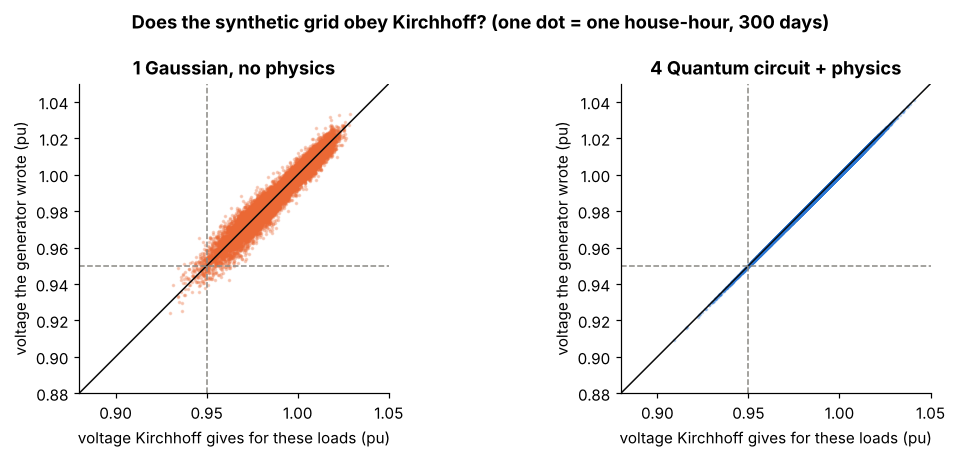

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, name in zip(ax, ["1 Gaussian, no physics", "4 Quantum circuit + physics"]):
    P, V, _ = models[name]
    a.scatter(power_flow(P[:300]).ravel(), V[:300].ravel(), s=2, alpha=0.25, color=COLORS[name], rasterized=True)
    a.plot([0.88, 1.05], [0.88, 1.05], color=INK, lw=1)
    a.axvline(V_LIMIT, color=GRAY, ls="--", lw=1); a.axhline(V_LIMIT, color=GRAY, ls="--", lw=1)
    a.set_xlim(0.88, 1.05); a.set_ylim(0.88, 1.05); a.set_aspect("equal")
    a.set_xlabel("voltage Kirchhoff gives for these loads (pu)"); a.set_ylabel("voltage the generator wrote (pu)")
    a.set_title(name)
fig.suptitle("Does the synthetic grid obey Kirchhoff? (one dot = one house-hour, 300 days)", fontweight="bold")
plt.tight_layout(); plt.show()

On the black line the data is physically consistent. The no-physics generator scatters around it: its voltages are
typically about 1% off from what its own loads imply, which is a fifth of the whole allowed band. The physics
generators sit exactly on the line by construction.

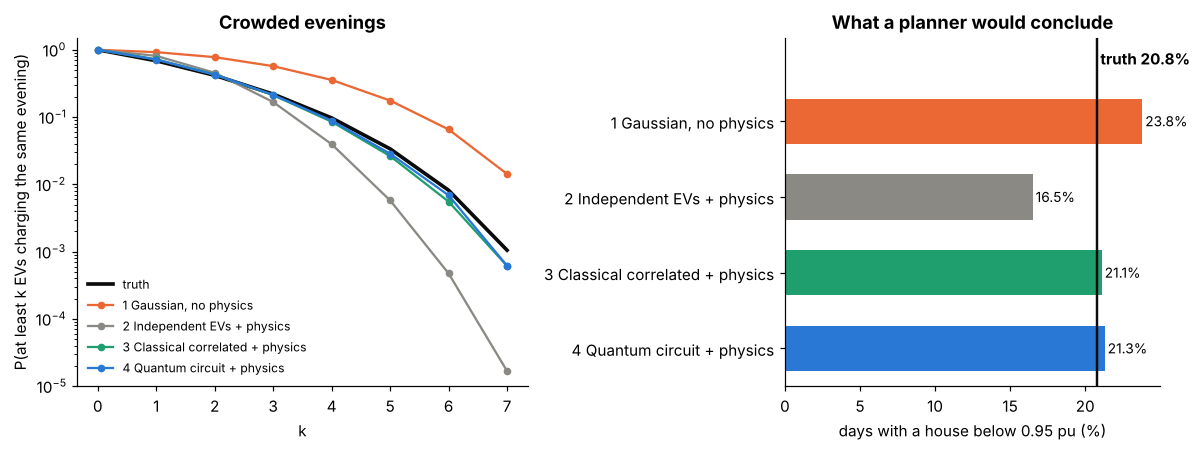

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ks = np.arange(NL + 1)
tail = lambda p: np.array([p[n_charging >= k].sum() for k in ks])
ax[0].semilogy(ks, tail(P_TRUE), color=INK, lw=2.4, label="truth")
for name, (P, V, p) in models.items():
    p = pattern_probs(P) if p is None else p
    ax[0].semilogy(ks, np.clip(tail(p), 1e-6, None), color=COLORS[name], marker="o", ms=4, label=name)
ax[0].set_xlabel("k"); ax[0].set_ylabel("P(at least k EVs charging the same evening)")
ax[0].set_ylim(1e-5, 1.5); ax[0].legend(frameon=False, fontsize=8); ax[0].set_title("Crowded evenings")

names = list(models)
vals = results.loc[names, "problem days (%)"].values
ax[1].barh(range(4), vals, color=[COLORS[n] for n in names], height=0.6)
ax[1].axvline(true_problem, color=INK, lw=1.6)
ax[1].text(true_problem, -0.75, f" truth {true_problem:.1f}%", fontweight="bold")
for i, v in enumerate(vals):
    ax[1].text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=9)
ax[1].set_yticks(range(4)); ax[1].set_yticklabels(names); ax[1].set_ylim(3.5, -1.1)
ax[1].set_xlabel(f"days with a house below {V_LIMIT} pu (%)"); ax[1].set_title("What a planner would conclude")
plt.tight_layout(); plt.show()

## 8. Conclusions

1. **Without physics the data describes an impossible grid.** Generator 1 learns roughly the right shapes, but its
   voltages do not match its loads, and blurring the loads also exaggerates EV charging.
2. **Physics alone is not enough.** Generator 2 is physically perfect, yet it treats houses as independent. It misses
   the crowded evenings and **under-estimates problem days by about a fifth**, telling the planner the street is
   safer than it is.
3. **Modelling the neighbour effect fixes the risk.** The quantum circuit, wired like the street, and the classical
   correlated model both land close to the true share of problem days. Both also beat simply counting the training
   days, because one year is too short to see the rare patterns.
4. **No quantum advantage at this size.** With 7 houses the classical model is exact and works just as well. The
   interest of the circuit is its design: the street layout lives in its wiring, and sampling is cheap. Whether that
   pays off for streets with hundreds of houses is an open question.

**Try it yourself:** change `J_COUP` (0 = no contagion), the cable resistances `R_LINE`, or the random seed in
section 3, and rerun everything.